The aim of this project is to predict whether a passenger survived the sinking of the Titanic, using a deep learning classification model built with Keras. The dataset contains demographic and travel information for each passenger, including ticket class, sex, age, number of family members on board, fare and port of embarkation. The target variable, Survived, is binary (0 = did not survive, 1 = survived), so the task is framed as a binary classification problem.

The project follows a standard workflow: exploring the data, handling missing values, encoding categorical variables, scaling the features, and then building, training and evaluating a feed-forward neural network. Model performance is assessed on a validation set held out from the training data, using accuracy and the loss and accuracy curves.

Data Dictionary

Survival= Survival
Pclass= Ticket Class
Sex= Sex
Age= Age in years
Sibsp= # of siblings/spouses aboard the Titanic
Parch= # of parents/children aboard the Titanic
Ticket= Ticket number
Fare= Passenger fare
Cabin= Cabin Number
Embarked= Port of Embarkation


In [1]:
import pandas as pd

In [2]:
df1=pd.read_csv('ttrain.csv')

In [3]:
df1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df2=pd.read_csv('ttest.csv')

In [5]:
df2.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [6]:
dft = pd.concat([df1, df2])

In [7]:
dft.isnull().sum()

PassengerId       0
Survived        418
Pclass            0
Name              0
Sex               0
Age             263
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2
dtype: int64

In [8]:
dft.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [9]:
dft=dft.drop(['Ticket','PassengerId','Cabin'], axis=1)

In [10]:
dft.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S
1,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C
2,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S
3,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S
4,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S


In [11]:
dft.shape

(1309, 9)

In [12]:
dft['Fare']=dft['Fare'].fillna(dft['Fare'].mean())

In [13]:
dft['Embarked']=dft['Embarked'].fillna(dft['Embarked'].mode()[0])

In [14]:
dft['Age'] = dft['Age'].fillna(dft.groupby('Pclass')['Age'].transform('median'))

In [15]:
dft.isnull().sum()

Survived    418
Pclass        0
Name          0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
dtype: int64

In [16]:
dft = dft.drop(['Name', 'Embarked'], axis=1)

In [17]:
dft = pd.get_dummies(dft, drop_first=True)

In [18]:
dft.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male
0,0.0,3,22.0,1,0,7.2500,True
1,1.0,1,38.0,1,0,71.2833,False
2,1.0,3,26.0,0,0,7.9250,False
3,1.0,1,35.0,1,0,53.1000,False
4,0.0,3,35.0,0,0,8.0500,True


In [19]:
dft.isnull().sum()

Survived    418
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
dtype: int64

In [20]:
train=dft[ :891]
test=dft[891: ]

In [21]:
x_train=train.drop('Survived',axis=1)
y_train=train['Survived']

In [22]:
from sklearn.preprocessing import StandardScaler

In [23]:
scaler=StandardScaler()

In [24]:
x_train=scaler.fit_transform(x_train)

In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import tensorflow as tf
tf.keras.utils.set_random_seed(23)

In [26]:
model=Sequential()
model.add(Dense(80,activation='relu')) 
model.add(Dense(120,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(30,activation='relu'))
model.add(Dense(8,activation='relu'))
model.add(Dense(1,activation='sigmoid')) 


model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [27]:
history=model.fit(x_train,y_train, batch_size=32,validation_split=0.20, verbose=2, epochs=100)

Epoch 1/100
23/23 - 4s - 195ms/step - accuracy: 0.6938 - loss: 0.6658 - val_accuracy: 0.8492 - val_loss: 0.6133
Epoch 2/100
23/23 - 0s - 12ms/step - accuracy: 0.7935 - loss: 0.5858 - val_accuracy: 0.8436 - val_loss: 0.4926
Epoch 3/100
23/23 - 0s - 12ms/step - accuracy: 0.7992 - loss: 0.4819 - val_accuracy: 0.8547 - val_loss: 0.3662
Epoch 4/100
23/23 - 0s - 19ms/step - accuracy: 0.8076 - loss: 0.4376 - val_accuracy: 0.8492 - val_loss: 0.3604
Epoch 5/100
23/23 - 0s - 11ms/step - accuracy: 0.8174 - loss: 0.4262 - val_accuracy: 0.8771 - val_loss: 0.3511
Epoch 6/100
23/23 - 0s - 13ms/step - accuracy: 0.8146 - loss: 0.4225 - val_accuracy: 0.8771 - val_loss: 0.3467
Epoch 7/100
23/23 - 0s - 11ms/step - accuracy: 0.8146 - loss: 0.4158 - val_accuracy: 0.8771 - val_loss: 0.3465
Epoch 8/100
23/23 - 0s - 11ms/step - accuracy: 0.8132 - loss: 0.4118 - val_accuracy: 0.8715 - val_loss: 0.3473
Epoch 9/100
23/23 - 0s - 11ms/step - accuracy: 0.8132 - loss: 0.4097 - val_accuracy: 0.8715 - val_loss: 0.3392


In [28]:
loss,accuracy=model.evaluate(x_train,y_train)

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8743 - loss: 0.3280


In [29]:
accuracy

0.8742985129356384

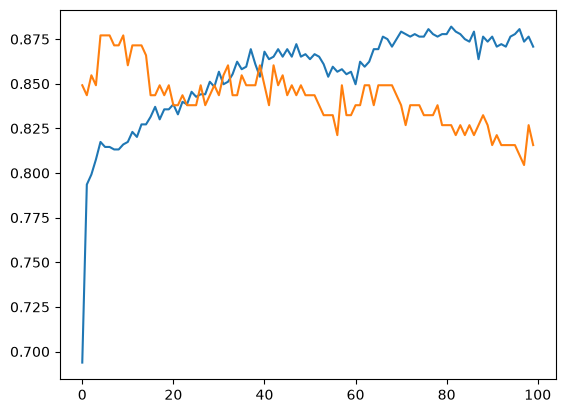

In [30]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy']);

Interpretation of the Accuracy Curves

The training accuracy (blue) rises steadily throughout training, from about 0.69 to 0.88. The validation accuracy (orange), however, reaches its best level of around 0.87–0.88 in the first 15 epochs and then gradually declines, falling to about 0.80–0.83 in the final epochs. The two curves meet at around epochs 20–40, after which the training accuracy keeps improving while the validation accuracy decreases, so the gap between them widens. This pattern indicates overfitting: beyond this point, the model starts to memorise the training data rather than learning patterns that generalise to unseen passengers. To address this, the model is retrained below using early stopping, which halts training once the validation loss stops improving and keeps the weights from the best epoch.

In [31]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss',
                           patience=10,
                           restore_best_weights=True)

In [32]:
model2 = Sequential()
model2.add(Dense(80, activation='relu'))
model2.add(Dense(120, activation='relu'))
model2.add(Dense(64, activation='relu'))
model2.add(Dense(30, activation='relu'))
model2.add(Dense(8, activation='relu'))
model2.add(Dense(1, activation='sigmoid'))

model2.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

history2 = model2.fit(x_train, y_train,
                      batch_size=32,
                      validation_split=0.20,
                      epochs=100,
                      callbacks=[early_stop],
                      verbose=2)

Epoch 1/100
23/23 - 6s - 256ms/step - accuracy: 0.7331 - loss: 0.6618 - val_accuracy: 0.8268 - val_loss: 0.5935
Epoch 2/100
23/23 - 0s - 20ms/step - accuracy: 0.8020 - loss: 0.5554 - val_accuracy: 0.8324 - val_loss: 0.4400
Epoch 3/100
23/23 - 0s - 11ms/step - accuracy: 0.8090 - loss: 0.4570 - val_accuracy: 0.8436 - val_loss: 0.3819
Epoch 4/100
23/23 - 0s - 10ms/step - accuracy: 0.8132 - loss: 0.4307 - val_accuracy: 0.8380 - val_loss: 0.3717
Epoch 5/100
23/23 - 0s - 10ms/step - accuracy: 0.8230 - loss: 0.4264 - val_accuracy: 0.8492 - val_loss: 0.3568
Epoch 6/100
23/23 - 0s - 10ms/step - accuracy: 0.8216 - loss: 0.4241 - val_accuracy: 0.8547 - val_loss: 0.3461
Epoch 7/100
23/23 - 0s - 10ms/step - accuracy: 0.8188 - loss: 0.4246 - val_accuracy: 0.8715 - val_loss: 0.3530
Epoch 8/100
23/23 - 0s - 10ms/step - accuracy: 0.8174 - loss: 0.4172 - val_accuracy: 0.8771 - val_loss: 0.3510
Epoch 9/100
23/23 - 1s - 26ms/step - accuracy: 0.8160 - loss: 0.4113 - val_accuracy: 0.8771 - val_loss: 0.3428


In [33]:
loss,accuracy=model2.evaluate(x_train,y_train)

28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8552 - loss: 0.3683


In [34]:
accuracy

0.8552188277244568

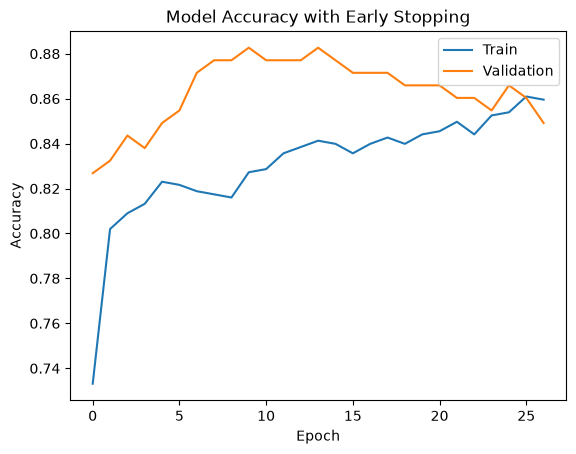

In [35]:
import matplotlib.pyplot as plt
plt.plot(history2.history['accuracy'])
plt.plot(history2.history['val_accuracy'])
plt.title('Model Accuracy with Early Stopping')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show();

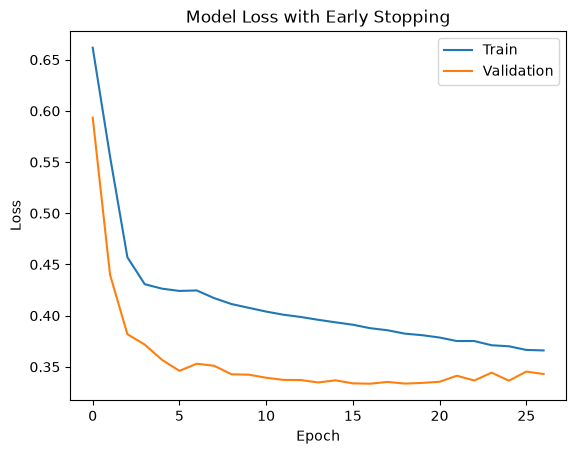

In [36]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])
plt.title('Model Loss with Early Stopping')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()

In this project, a feed-forward neural network was built with Keras to predict passenger survival on the Titanic. After the missing values in Age, Fare and Embarked were handled, irrelevant columns were dropped and the Sex variable was encoded. The model was then trained on six features: ticket class, sex, age, number of siblings/spouses, number of parents/children and fare. All features were standardised before training.

The first model was trained for 100 epochs. It reached a validation accuracy of around 0.86–0.88 in the early epochs but then began to overfit: the training accuracy kept rising to about 0.88, while the validation accuracy fell to around 0.80–0.83 in the final epochs and the validation loss increased steadily. To address this, the model was retrained with early stopping, which monitored the validation loss and restored the weights from the best epoch. Training stopped after 27 epochs, and the weights from epoch 17 were restored, where the model achieved a validation accuracy of about 0.87. Throughout this run, the validation accuracy remained between 0.85 and 0.88 with no sign of overfitting.
